# Revised Heart-Rate Estimation Pipeline (rPPG)

This notebook is the revision of your original `Heart_rate_model__2_.ipynb`,
addressing **all 9 reviewer comments**. Read `REVISION_GUIDE.md` first if you
haven't — it explains the *why* behind every change here.

**What this notebook does, in order**

| § | Step | Reviewer points addressed |
|---|------|--------------------------|
| 1 | Imports and config | – |
| 2 | Per-video feature extraction (ViT + POS + EVM) | 2, 3, 5 |
| 3 | Build per-subject CSV of features and ground-truth HR | – |
| 4 | LOSO subject-wise evaluation loop | 1 |
| 5 | The fixed LSTM model (no `relu` bug) | 5 |
| 6 | Ablations: Full / ViT-only / POS-only / MLP-head | 4 |
| 7 | Classical baselines: GREEN / CHROM / POS / ICA / PCA | 3, 4 |
| 8 | Metrics, Bland-Altman, stratified errors | 6, 8 |
| 9 | Pipeline profiling (latency / fps) | 7 |

**Required files in the same folder**
- `rppg_baselines.py`
- `evaluation.py`
- `data/` (UBFC-style: each subject in a sub-folder containing `vid.avi` and `ground_truth.txt`)


## 1. Imports and configuration

All "magic numbers" live in this one cell — change them once here and the
whole pipeline picks up the new value.

> **Newbie note:** if any import fails, install with `pip install <package>`.
> You'll need: `numpy pandas scipy scikit-learn matplotlib opencv-python torch torchvision transformers`.


In [ ]:
# Standard library
import os, time, glob, json
from pathlib import Path

# Numerical / data
import numpy as np
import pandas as pd
import scipy.signal as signal
import matplotlib.pyplot as plt

# CV / DL
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import ViTModel
from sklearn.preprocessing import StandardScaler

# Local helpers
from rppg_baselines import (extract_rgb_from_video, pos_method,
                            chrom_method, ica_method, pca_method,
                            green_method, hr_from_bvp, signal_snr_db,
                            bandpass_filter, windowed_hr)
from evaluation import (loso_split, subject_kfold_split,
                        compute_all_metrics, aggregate_metrics,
                        bland_altman_plot, stratified_errors,
                        stratified_error_plot, estimate_motion,
                        estimate_skin_tone_luma, profile_pipeline,
                        time_block)

# Check for GPU availability
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f"PyTorch: {torch.__version__} | Hardware Acceleration: Apple MPS")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"PyTorch: {torch.__version__} | Hardware Acceleration: NVIDIA CUDA")
else:
    device = torch.device("cpu")
    print(f"PyTorch: {torch.__version__} | Hardware Acceleration: CPU")


PyTorch: 2.11.0 | Hardware Acceleration: Apple MPS


In [ ]:
# -------------- CONFIG (edit these) --------------
DATA_ROOT = Path("/Users/olarenwaju/Desktop/DATASET_2")        # contains one folder per subject
FEATURES_CSV  = Path('./features.csv')  # cached per-frame features per subject
RESULTS_DIR   = Path('./results')
RESULTS_DIR.mkdir(exist_ok=True)

# rPPG band - 0.7-4.0 Hz covers 42-240 BPM. DO NOT use the 50-60 BPM band
# from the original code; that was the reviewer-noted bug.
F_LO_HZ = 0.7
F_HI_HZ = 4.0

# Sliding-window settings for HR estimation and LSTM input
WIN_SECONDS  = 10.0     # window length in seconds for HR estimation
STEP_SECONDS = 1.0      # 1 estimate per second matches UBFC ground truth

# ViT
VIT_MODEL_NAME = 'google/vit-base-patch16-224'
VIT_HIDDEN     = 768                    # native CLS token dim
VIT_PROJ       = 64                     # we project down to keep params low

# LSTM (the FIXED version - no relu)
LSTM_HIDDEN  = 64
LSTM_LAYERS  = 2
LSTM_DROPOUT = 0.2
LSTM_BIDIR   = True

# Training
BATCH_SIZE   = 32
EPOCHS       = 30
LR           = 1e-3
SEED         = 0

# Run faster K-fold instead of full LOSO during development?
USE_KFOLD = True
KFOLDS    = 5

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print('Using device:', DEVICE)


Using device: mps


In [ ]:
print("DATA_ROOT =", DATA_ROOT)
print("Exists?", DATA_ROOT.exists())
if DATA_ROOT.exists():
    subs = sorted([d.name for d in DATA_ROOT.iterdir() if d.is_dir()])
    print(f"Found {len(subs)} subject folders.")
    print("First few:", subs[:5])
    # Peek inside the first subject
    if subs:
        first = DATA_ROOT / subs[0]
        contents = sorted(f.name for f in first.iterdir())
        print(f"\nContents of {subs[0]}:", contents)

DATA_ROOT = /Users/olarenwaju/Desktop/DATASET_2
Exists? True
Found 3 subject folders.
First few: ['__pycache__', 'cache', 'results']

Contents of __pycache__: ['evaluation.cpython-313.pyc', 'rppg_baselines.cpython-313.pyc']


## 2. Per-video feature extraction

For each video we extract three feature streams (one row per frame):

1. **POS rPPG signal** — replaces the broken "stack" feature in your old code.
   Computed by the POS algorithm on **color** (RGB) face mean values, in the
   correct cardiac band 0.7-4 Hz. Addresses reviewer points 2 and 3.
2. **EVM-derived signal** — *fixed* version of the Eulerian Video Magnification
   feature you had. Instead of one pixel of the level-4 pyramid, we average
   over the *whole* small ROI patch and bandpass-filter it. Color-aware.
3. **ViT CLS feature** — projected from 768 dimensions down to 64. The original
   code only used dim 0 of 768; we use *all* of them via a learned projection.
   Addresses reviewer point 5.

We also keep the per-frame face bounding box for motion estimation later.


In [26]:

# ---------- Face detector (one global instance) ----------
FACE_CASCADE = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')

# ---------- ViT feature extractor ----------
class ViTBackbone(nn.Module):
    """Frozen ViT-Base/16; outputs the 768-D CLS token per image."""
    def __init__(self, model_name=VIT_MODEL_NAME):
        super().__init__()
        self.vit = ViTModel.from_pretrained(model_name)
        for p in self.vit.parameters():
            p.requires_grad = False
        self.eval()

    def forward(self, x):
        # x: (B, 3, 224, 224)
        out = self.vit(pixel_values=x)
        return out.last_hidden_state[:, 0, :]   # (B, 768) - CLS token

VIT_TRANSFORM = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3),
])

print('Loading ViT backbone (only on first run)...')
VIT_BACKBONE = ViTBackbone().to(DEVICE)
print('Frozen ViT params:', sum(p.numel() for p in VIT_BACKBONE.parameters()))


Loading ViT backbone (only on first run)...


[ERROR:0@30386.292] global persistence.cpp:566 open Can't open file: 'haarcascade_frontalface_default.xml' in read mode
Loading weights: 100%|██████████| 198/198 [00:00<00:00, 5136.17it/s]
ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Frozen ViT params: 86389248


In [27]:
def extract_features_for_video(video_path, batch_size=16):
    """
    Run face detection, ViT, POS, and EVM on one video.

    Returns a dict with arrays of length T (number of frames):
        'fs'         : float, video sampling rate (Hz)
        'face_boxes' : (T, 4) bounding boxes (x, y, w, h)
        'rgb'        : (T, 3) mean RGB of face skin
        'pos'        : (T,)   POS rPPG signal
        'evm'        : (T,)   EVM-derived signal (fixed; mean of small ROI patch)
        'vit'        : (T, 768) raw ViT CLS features
    """
    cap = cv2.VideoCapture(str(video_path))
    fs  = cap.get(cv2.CAP_PROP_FPS)
    if fs <= 0 or np.isnan(fs):
        fs = 30.0  # UBFC default

    boxes = []
    rgb_rows = []
    evm_rows = []
    vit_inputs = []

    last_box = None
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # ---- Face detection (grayscale OK for Haar; rPPG below uses color) ----
        gray  = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = FACE_CASCADE.detectMultiScale(gray, 1.1, 4)
        if len(faces) > 0:
            last_box = max(faces, key=lambda b: b[2]*b[3])
        if last_box is None:
            # No face yet; skip frame
            continue

        x, y, w, h = last_box
        boxes.append([x, y, w, h])

        face_bgr = frame[y:y+h, x:x+w]

        # ---- Mean RGB of the face skin (color-aware!) ----
        ycrcb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2YCrCb)
        skin  = ((ycrcb[..., 1] >= 133) & (ycrcb[..., 1] <= 173) &
                 (ycrcb[..., 2] >= 77)  & (ycrcb[..., 2] <= 127))
        if skin.sum() < 50:
            skin = np.ones(face_bgr.shape[:2], dtype=bool)
        b = float(face_bgr[..., 0][skin].mean())
        g = float(face_bgr[..., 1][skin].mean())
        r = float(face_bgr[..., 2][skin].mean())
        rgb_rows.append([r, g, b])

        # ---- EVM-style feature: mean of a small forehead patch ----
        # FIXED: previously used one pixel; here we use a (h//6 x w//4) patch.
        ph, pw = max(1, h // 6), max(1, w // 4)
        cy, cx = h // 5, w // 2  # forehead-ish
        y1, y2 = max(0, cy - ph // 2), min(h, cy + ph // 2)
        x1, x2 = max(0, cx - pw // 2), min(w, cx + pw // 2)
        patch = face_bgr[y1:y2, x1:x2]
        if patch.size > 0:
            # Average the green channel of the patch (strongest pulse signal)
            evm_rows.append(float(patch[..., 1].mean()))
        else:
            evm_rows.append(g)

        # ---- ViT input ----
        face_rgb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)
        vit_inputs.append(VIT_TRANSFORM(face_rgb))

    cap.release()

    if len(rgb_rows) == 0:
        raise RuntimeError(f'No faces detected in {video_path}')

    # ---- Run ViT in batches ----
    vit_feats = []
    with torch.no_grad():
        for i in range(0, len(vit_inputs), batch_size):
            batch = torch.stack(vit_inputs[i:i+batch_size]).to(DEVICE)
            feat  = VIT_BACKBONE(batch).cpu().numpy()
            vit_feats.append(feat)
    vit_feats = np.concatenate(vit_feats, axis=0)   # (T, 768)

    rgb = np.asarray(rgb_rows, dtype=np.float64)
    evm_raw = np.asarray(evm_rows, dtype=np.float64)

    # ---- POS rPPG (color-aware, correct band) ----
    pos_sig = pos_method(rgb, fs)

    # ---- EVM bandpassed in the cardiac band ----
    evm_sig = bandpass_filter(evm_raw - evm_raw.mean(), fs,
                              f_lo=F_LO_HZ, f_hi=F_HI_HZ)

    return dict(
        fs=fs,
        face_boxes=np.asarray(boxes),
        rgb=rgb,
        pos=pos_sig,
        evm=evm_sig,
        vit=vit_feats,
    )


## 3. Build per-subject feature dataframes

UBFC `ground_truth.txt` row 1 is the BVP signal, row 2 is HR in BPM at
the video's frame rate. We:
- Read each subject's video and ground truth.
- Extract features (Section 2).
- Save everything to disk so we don't re-extract for every experiment.

> If you've already run this once and `cache/<subject>.npz` exists, the cell
> will skip extraction and just load.


In [28]:
def load_ubfc_ground_truth(gt_path, n_frames):
    """Read UBFC ground_truth.txt and return HR per frame, length n_frames.

    UBFC format: row 0 = BVP signal (PPG waveform), row 1 = HR trace,
    row 2 = timestamps (seconds). Row 1 has sentinel values (1, 127) on
    several subjects, so we re-derive HR from row 0 using sliding-window
    Welch PSD — same method we use on rPPG predictions. This is internally
    consistent and works on every subject.
    """
    from rppg_baselines import bandpass_filter, hr_from_bvp

    arr = np.loadtxt(gt_path)
    bvp = arr[0, :].astype(float)
    t   = arr[2, :].astype(float)

    # Sampling rate from timestamps (UBFC: ~30 Hz)
    fs_gt = 1.0 / np.median(np.diff(t))

    # Bandpass to physiological range (0.7-4 Hz = 42-240 BPM)
    bvp_bp = bandpass_filter(bvp, fs_gt, f_lo=0.7, f_hi=4.0)

    # Sliding-window HR estimation, same as we'll do on predictions
    win_len = int(10 * fs_gt)            # 10-sec window
    step    = max(1, int(0.5 * fs_gt))   # 0.5-sec hop

    hr_per_t = np.full(len(bvp), np.nan)
    for s in range(0, len(bvp) - win_len + 1, step):
        e = s + win_len
        hr_per_t[(s + e) // 2] = hr_from_bvp(bvp_bp[s:e], fs_gt)

    # Fill the NaN edges with the nearest computed value
    valid = np.isfinite(hr_per_t)
    if valid.sum() < 5:
        return np.full(n_frames, np.nan)
    idx = np.arange(len(hr_per_t))
    hr_per_t = np.interp(idx, idx[valid], hr_per_t[valid])

    # Resample from BVP timeline (~30 Hz, len ~2020) to video frame count
    if len(hr_per_t) == n_frames:
        return hr_per_t
    x_old = np.linspace(0, 1, len(hr_per_t))
    x_new = np.linspace(0, 1, n_frames)
    return np.interp(x_new, x_old, hr_per_t)


In [29]:
try:
    print("DATA_ROOT:", DATA_ROOT)
except NameError:
    print("DATA_ROOT: NOT DEFINED")
try:
    print("Path:", Path)
except NameError:
    print("Path: NOT DEFINED")
try:
    print("np:", np)
except NameError:
    print("np: NOT DEFINED")
try:
    print("RESULTS_DIR:", RESULTS_DIR)
except NameError:
    print("RESULTS_DIR: NOT DEFINED")

DATA_ROOT: /Users/olarenwaju/Desktop/DATASET_2
Path: <class 'pathlib.Path'>
np: <module 'numpy' from '/opt/anaconda3/envs/heartrate/lib/python3.11/site-packages/numpy/__init__.py'>
RESULTS_DIR: results


In [30]:
def update_hr_in_caches(data_root=DATA_ROOT, cache_dir=Path('./cache')):
    """Replace the HR field in every cache with values re-derived from BVP.
    Leaves ViT, POS, EVM features untouched (they don't depend on HR)."""
    flagged = []
    for cache_file in sorted(cache_dir.glob('subject*.npz')):
        subj = cache_file.stem
        gt = data_root / subj / 'ground_truth.txt'
        if not gt.exists():
            print(f'  [skip] {subj}: no ground_truth.txt')
            continue

        data = dict(np.load(cache_file, allow_pickle=True))
        n_frames = len(data['rgb'])

        old_mean = float(np.nanmean(data['hr']))
        old_std  = float(np.nanstd(data['hr']))

        new_hr = load_ubfc_ground_truth(gt, n_frames)
        data['hr'] = new_hr

        new_mean = float(np.nanmean(new_hr))
        new_std  = float(np.nanstd(new_hr))

        np.savez(cache_file, **data)

        was_broken = old_std > 15
        if was_broken:
            flagged.append(subj)
        marker = '  *** FIXED ***' if was_broken else ''
        print(f'  {subj}: old {old_mean:5.1f}±{old_std:5.2f}  ->  '
              f'new {new_mean:5.1f}±{new_std:5.2f}{marker}')
    print(f'\nDone. {len(flagged)} subjects had broken row 1 and are now repaired:',
          flagged)

update_hr_in_caches()


Done. 0 subjects had broken row 1 and are now repaired: []


In [36]:
import numpy as np
from scipy import signal as sp
import rppg_baselines
from rppg_baselines import bandpass_filter

subj = "subject1"
arr = np.loadtxt(DATA_ROOT / subj / "ground_truth.txt")
bvp, t = arr[0].astype(float), arr[2].astype(float)
fs = 1.0 / np.median(np.diff(t))
bp = bandpass_filter(bvp, fs, 0.7, 4.0)

def hr_old(x, fs):                      # the original: 6s window, no padding, 4 Hz
    f, p = sp.welch(x, fs=fs, nperseg=min(len(x), int(6*fs)))
    b = (f >= 0.7) & (f <= 4.0)
    return f[b][p[b].argmax()] * 60

L, S = int(10*fs), max(1, int(0.5*fs))
old_tr, new_tr = [], []
for s in range(0, len(bp)-L+1, S):
    seg = bp[s:s+L]
    old_tr.append(hr_old(seg, fs))
    new_tr.append(rppg_baselines.hr_from_bvp(seg, fs))
old_tr, new_tr = np.array(old_tr), np.array(new_tr)

cache_hr = np.load(CACHE_DIR / f"{subj}.npz")["hr"]

print(f"OLD estimator : {old_tr.mean():7.2f} ± {old_tr.std():5.2f}   distinct values: {len(np.unique(np.round(old_tr,1)))}")
print(f"NEW estimator : {new_tr.mean():7.2f} ± {new_tr.std():5.2f}   distinct values: {len(np.unique(np.round(new_tr,1)))}")
print(f"cache holds   : {np.nanmean(cache_hr):7.2f} ± {np.nanstd(cache_hr):5.2f}")

OLD estimator :   96.20 ±  4.98   distinct values: 2
NEW estimator :   95.60 ±  3.20   distinct values: 52
cache holds   :   95.17 ±  3.89


In [31]:
import os
from pathlib import Path
print("working dir:", os.getcwd())
p = Path('./cache')
print("cache folder exists:", p.exists())
if p.exists():
    f = sorted(p.glob('subject*.npz'))
    print("npz files found:", len(f))
    print(f[:3])
print("DATA_ROOT:", DATA_ROOT, "| exists:", DATA_ROOT.exists())

working dir: /Users/olarenwaju/Downloads
cache folder exists: False
DATA_ROOT: /Users/olarenwaju/Desktop/DATASET_2 | exists: True


In [34]:
from pathlib import Path
import numpy as np

DATA_ROOT = Path("/Users/olarenwaju/Downloads/UBFC_DATASET2")
CACHE_DIR = Path("/Users/olarenwaju/Desktop/DATASET_2/cache")
print("DATA_ROOT =", DATA_ROOT, "| exists:", DATA_ROOT.exists())

# --- the two problem subjects ---
p = DATA_ROOT / "subject22"
print("\nsubject22 folder:", p.exists(), [f.name for f in p.iterdir()] if p.exists() else "")

gt = DATA_ROOT / "subject31" / "ground_truth.txt"
print("subject31 file:", gt.exists(), gt.stat().st_size if gt.exists() else "", "bytes")
if gt.exists():
    with open(gt) as f:
        for i in range(3):
            parts = next(f).split()
            print(f"  row {i}: {len(parts)} values | {parts[:3]}")

# --- the actual job ---
print("\n" + "="*60)
update_hr_in_caches(data_root=DATA_ROOT, cache_dir=CACHE_DIR)

DATA_ROOT = /Users/olarenwaju/Downloads/UBFC_DATASET2 | exists: True

subject22 folder: True ['.DS_Store', 'ground_truth.txt']
subject31 file: True 97309 bytes
  row 0: 2028 values | ['Subject', '4.1767144e-01', '1.4251330e+00']
  row 1: 2027 values | ['8.1000000e+01', '8.1000000e+01', '8.1000000e+01']
  row 2: 2027 values | ['0.0000000e+00', '2.6000000e-02', '6.8000000e-02']

  subject1: old  95.2± 3.89  ->  new  95.2± 3.89
  subject10: old 111.3± 9.71  ->  new 111.3± 9.71
  subject11: old 121.3± 5.13  ->  new 121.3± 5.13
  subject12: old  55.8± 1.54  ->  new  55.8± 1.54
  subject13: old 108.7± 8.09  ->  new 108.7± 8.09
  subject14: old  61.0± 4.96  ->  new  61.0± 4.96
  subject15: old 117.1± 3.90  ->  new 117.1± 3.90
  subject16: old  94.6± 2.65  ->  new  94.6± 2.65
  subject17: old  87.4± 2.82  ->  new  87.4± 2.82
  subject18: old 122.0± 8.62  ->  new 122.0± 8.62
  subject20: old 127.5± 7.87  ->  new 127.5± 7.87
  subject22: old 103.9± 7.46  ->  new 103.9± 7.46
  subject23: old  53.

ValueError: could not convert string 'Subject' to float64 at row 0, column 1.

In [22]:
from pathlib import Path
import numpy as np

DATA_ROOT = Path("/Users/olarenwaju/Downloads/UBFC_DATASET2")
CACHE_DIR = Path("/Users/olarenwaju/Desktop/DATASET_2/cache")

print("DATA_ROOT exists:", DATA_ROOT.exists())
print("top level:", sorted(p.name for p in DATA_ROOT.iterdir())[:8])
print()

caches = sorted(CACHE_DIR.glob("subject*.npz"))
print(f"cache files: {len(caches)}")

missing, bad, ok = [], [], 0
for c in caches:
    gt = DATA_ROOT / c.stem / "ground_truth.txt"
    if not gt.exists():
        missing.append(c.stem); continue
    try:
        a = np.loadtxt(gt)
        fs = 1.0 / np.median(np.diff(a[2, :]))
        if a.ndim != 2 or a.shape[0] < 3 or not (20 < fs < 70):
            bad.append((c.stem, f"shape {a.shape}, fs {fs:.1f}")); continue
        ok += 1
    except Exception as e:
        bad.append((c.stem, type(e).__name__))

print(f"ground truth OK : {ok}")
print(f"missing         : {len(missing)} {missing[:8]}")
print(f"malformed       : {len(bad)} {bad[:8]}")

DATA_ROOT exists: True
top level: ['.DS_Store', 'subject1', 'subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15']

cache files: 42
ground truth OK : 40
missing         : 1 ['subject22']
malformed       : 1 [('subject31', 'ValueError')]


In [10]:
CACHE_DIR = Path("/Users/olarenwaju/Desktop/DATASET_2/cache")
print(len(list(CACHE_DIR.glob("subject*.npz"))), "cache files")

update_hr_in_caches(data_root=DATA_ROOT, cache_dir=CACHE_DIR)

42 cache files
  [skip] subject1: no ground_truth.txt
  [skip] subject10: no ground_truth.txt
  [skip] subject11: no ground_truth.txt
  [skip] subject12: no ground_truth.txt
  [skip] subject13: no ground_truth.txt
  [skip] subject14: no ground_truth.txt
  [skip] subject15: no ground_truth.txt
  [skip] subject16: no ground_truth.txt
  [skip] subject17: no ground_truth.txt
  [skip] subject18: no ground_truth.txt
  [skip] subject20: no ground_truth.txt
  [skip] subject22: no ground_truth.txt
  [skip] subject23: no ground_truth.txt
  [skip] subject24: no ground_truth.txt
  [skip] subject25: no ground_truth.txt
  [skip] subject26: no ground_truth.txt
  [skip] subject27: no ground_truth.txt
  [skip] subject3: no ground_truth.txt
  [skip] subject30: no ground_truth.txt
  [skip] subject31: no ground_truth.txt
  [skip] subject32: no ground_truth.txt
  [skip] subject33: no ground_truth.txt
  [skip] subject34: no ground_truth.txt
  [skip] subject35: no ground_truth.txt
  [skip] subject36: no grou

In [12]:
CACHE_DIR = Path("/Users/olarenwaju/Desktop/DATASET_2/cache")
print(len(list(CACHE_DIR.glob("subject*.npz"))), "cache files")
update_hr_in_caches(data_root=DATA_ROOT, cache_dir=CACHE_DIR)

42 cache files
  [skip] subject1: no ground_truth.txt
  [skip] subject10: no ground_truth.txt
  [skip] subject11: no ground_truth.txt
  [skip] subject12: no ground_truth.txt
  [skip] subject13: no ground_truth.txt
  [skip] subject14: no ground_truth.txt
  [skip] subject15: no ground_truth.txt
  [skip] subject16: no ground_truth.txt
  [skip] subject17: no ground_truth.txt
  [skip] subject18: no ground_truth.txt
  [skip] subject20: no ground_truth.txt
  [skip] subject22: no ground_truth.txt
  [skip] subject23: no ground_truth.txt
  [skip] subject24: no ground_truth.txt
  [skip] subject25: no ground_truth.txt
  [skip] subject26: no ground_truth.txt
  [skip] subject27: no ground_truth.txt
  [skip] subject3: no ground_truth.txt
  [skip] subject30: no ground_truth.txt
  [skip] subject31: no ground_truth.txt
  [skip] subject32: no ground_truth.txt
  [skip] subject33: no ground_truth.txt
  [skip] subject34: no ground_truth.txt
  [skip] subject35: no ground_truth.txt
  [skip] subject36: no grou

## 4. The fixed LSTM model (no `relu` bug)

This is the corrected version of your model. Differences from the original:

| Original | Fixed | Why |
|----------|-------|-----|
| `LSTM(activation='relu')` | default `tanh` cell, `sigmoid` gates | LSTMs use tanh/sigmoid by design; `relu` breaks gating. Reviewer flagged this. |
| 1 layer, 30 hidden units | 2 layers, 64 hidden, dropout 0.2, **bidirectional** | Standard rPPG temporal head. |
| 3 hand-picked features per frame | ViT(768→64) + POS + EVM = 66 features | Uses the full ViT signal. |

**Parameter count (trainable):**
- ViT projection 768→64:   ~50K
- BiLSTM 66→64×2 layers:   ~100K
- Linear head 128→1:        129
- Total trainable:         ~150K (the frozen ViT-Base adds 86M, not trainable)


In [38]:
class HRRegressor(nn.Module):
    """
    Combines projected ViT features with the rPPG signals (POS, EVM)
    into a per-window HR estimate via a BiLSTM.

    Input  : (B, T, 768 + 2)  - ViT CLS + POS + EVM per frame
    Output : (B, 1) HR estimate in BPM (regression)
    """
    def __init__(self, vit_dim=VIT_HIDDEN, vit_proj=VIT_PROJ,
                 hidden=LSTM_HIDDEN, layers=LSTM_LAYERS,
                 dropout=LSTM_DROPOUT, bidir=LSTM_BIDIR,
                 use_vit=True, use_pos=True, use_evm=True):
        super().__init__()
        self.use_vit = use_vit
        self.use_pos = use_pos
        self.use_evm = use_evm

        # Linear projection of ViT 768 -> 64 (so the LSTM input isn't huge)
        self.vit_proj = nn.Linear(vit_dim, vit_proj) if use_vit else None

        in_dim = (vit_proj if use_vit else 0) + (1 if use_pos else 0) + (1 if use_evm else 0)
        if in_dim == 0:
            raise ValueError('Must enable at least one feature stream.')

        self.lstm = nn.LSTM(
            input_size=in_dim,
            hidden_size=hidden,
            num_layers=layers,
            batch_first=True,
            dropout=dropout if layers > 1 else 0.0,
            bidirectional=bidir,
        )
        out_dim = hidden * (2 if bidir else 1)
        self.head = nn.Linear(out_dim, 1)

    def forward(self, vit, pos, evm):
        # vit: (B, T, 768) ; pos: (B, T, 1) ; evm: (B, T, 1)
        parts = []
        if self.use_vit:
            parts.append(self.vit_proj(vit))
        if self.use_pos:
            parts.append(pos)
        if self.use_evm:
            parts.append(evm)
        x = torch.cat(parts, dim=-1)            # (B, T, in_dim)
        out, _ = self.lstm(x)                   # (B, T, out_dim)
        # Take the LAST timestep representation for HR regression
        return self.head(out[:, -1, :])         # (B, 1)


# Quick sanity check
m = HRRegressor()
print('Trainable params:',
      sum(p.numel() for p in m.parameters() if p.requires_grad))
B, T = 4, 300
v = torch.randn(B, T, VIT_HIDDEN)
p = torch.randn(B, T, 1)
e = torch.randn(B, T, 1)
print('Output shape:', m(v, p, e).shape)   # expect (4, 1)


Trainable params: 216257
Output shape: torch.Size([4, 1])


## 5. Window dataset

For each video we slice a sliding window of `WIN_SECONDS` (default 10 s).
Each window:
- input: (T_window, ViT 768) + (T_window,) POS + (T_window,) EVM
- target: ground-truth HR at the END of the window (matching `windowed_hr`)

We standardize features *per training fold* using only training subjects'
statistics, to avoid leakage (reviewer point 1).


In [39]:
# Target sampling rate for windowing. UBFC is 30 fps nominal.
# Using a fixed value here means every window has the same length L,
# so PyTorch can stack them into batches cleanly.
TARGET_FS = 30
WIN_LEN   = int(WIN_SECONDS * TARGET_FS)   # 300 frames for 10s
WIN_STEP  = max(1, int(STEP_SECONDS * TARGET_FS))   # 30 frames for 1s

class HRWindowDataset(Dataset):
    def __init__(self, cache_paths, win_seconds=WIN_SECONDS,
                 step_seconds=STEP_SECONDS, scaler_pos=None, scaler_evm=None,
                 fit_scalers=False):
        self.windows = []
        self.caches  = [dict(np.load(p, allow_pickle=True)) for p in cache_paths]

        # Use a FIXED window length and step across all subjects so DataLoader
        # can batch them. We assume nominal 30 Hz; small fs deviations are absorbed.
        L    = WIN_LEN
        step = WIN_STEP

        all_pos, all_evm = [], []
        for ci, c in enumerate(self.caches):
            # Align all streams to the shortest length for this subject.
            T = min(len(c['pos']), len(c['evm']), len(c['vit']), len(c['hr']))
            c['pos'] = np.asarray(c['pos'][:T], dtype=np.float32)
            c['evm'] = np.asarray(c['evm'][:T], dtype=np.float32)
            c['vit'] = np.asarray(c['vit'][:T], dtype=np.float32)
            c['hr']  = np.asarray(c['hr'][:T],  dtype=np.float32)

            for s in range(0, T - L + 1, step):
                e = s + L
                hr_t = float(c['hr'][(s + e) // 2])
                if not np.isfinite(hr_t) or not (40.0 <= hr_t <= 200.0):
                    continue
                self.windows.append((ci, s, e, hr_t))
            all_pos.append(c['pos'])
            all_evm.append(c['evm'])

        all_pos = np.concatenate(all_pos).reshape(-1, 1)
        all_evm = np.concatenate(all_evm).reshape(-1, 1)
        if fit_scalers:
            self.scaler_pos = StandardScaler().fit(all_pos)
            self.scaler_evm = StandardScaler().fit(all_evm)
        else:
            assert scaler_pos is not None and scaler_evm is not None
            self.scaler_pos = scaler_pos
            self.scaler_evm = scaler_evm

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        ci, s, e, hr_t = self.windows[idx]
        c = self.caches[ci]

        vit_arr = c['vit'][s:e]                                       # (L, 768)
        pos_arr = self.scaler_pos.transform(c['pos'][s:e].reshape(-1, 1))  # (L, 1)
        evm_arr = self.scaler_evm.transform(c['evm'][s:e].reshape(-1, 1))  # (L, 1)

        # Sanity check — every sample MUST have length L. If not, skip cleanly.
        if vit_arr.shape[0] != WIN_LEN or pos_arr.shape[0] != WIN_LEN or evm_arr.shape[0] != WIN_LEN:
            raise RuntimeError(
                f"Window length mismatch at idx {idx}: "
                f"vit={vit_arr.shape}, pos={pos_arr.shape}, evm={evm_arr.shape}, expected L={WIN_LEN}"
            )

        # Use torch.as_tensor (handles both numpy and tensor inputs without warning)
        vit = torch.as_tensor(np.ascontiguousarray(vit_arr), dtype=torch.float32)
        pos = torch.as_tensor(np.ascontiguousarray(pos_arr), dtype=torch.float32)
        evm = torch.as_tensor(np.ascontiguousarray(evm_arr), dtype=torch.float32)
        y   = torch.as_tensor([hr_t], dtype=torch.float32)
        return vit, pos, evm, y

print(f"Dataset config: WIN_LEN={WIN_LEN} frames, WIN_STEP={WIN_STEP} frames "
      f"(at TARGET_FS={TARGET_FS} Hz)")

Dataset config: WIN_LEN=300 frames, WIN_STEP=30 frames (at TARGET_FS=30 Hz)


## 6. LOSO training and evaluation loop

This is the **biggest** change from your original code. For each subject `s`:
1. Build a training dataset from all *other* subjects.
2. Fit standardizers on training subjects only (no leakage).
3. Train the LSTM for a few epochs.
4. Predict on subject `s`, log per-window predictions.
5. Compute all metrics for that subject.

After looping, we aggregate (mean ± SD across subjects) and save:
- `results/loso_per_subject.csv`
- `results/loso_predictions.csv` (every prediction, for plots later)


In [41]:
import os
os.chdir("/Users/olarenwaju/Desktop/DATASET_2")
print("now working in:", os.getcwd())
print("results/ exists:", os.path.isdir("results"))
print("cache/ exists:", os.path.isdir("cache"))
print("subject_summary.csv:", os.path.isfile("results/subject_summary.csv"))

now working in: /Users/olarenwaju/Desktop/DATASET_2
results/ exists: True
cache/ exists: True
subject_summary.csv: True


In [40]:
def train_one_fold(train_paths, model_kwargs, epochs=EPOCHS, lr=LR,
                   batch_size=BATCH_SIZE, verbose=False):
    """Build dataset, build model, train. Return model, scalers, train_history."""
    ds = HRWindowDataset(train_paths, fit_scalers=True)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0)
    model = HRRegressor(**model_kwargs).to(DEVICE)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    loss_fn = nn.SmoothL1Loss()        # robust HR regression
    history = []
    for ep in range(epochs):
        model.train()
        epoch_losses = []
        for vit, pos, evm, y in loader:
            vit, pos, evm, y = vit.to(DEVICE), pos.to(DEVICE), evm.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            pred = model(vit, pos, evm)
            loss = loss_fn(pred, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            epoch_losses.append(loss.item())
        history.append(np.mean(epoch_losses))
        if verbose:
            print(f'  epoch {ep+1:02d}/{epochs}  loss={history[-1]:.3f}')
    return model, ds.scaler_pos, ds.scaler_evm, history


def eval_one_fold(model, scaler_pos, scaler_evm, test_path):
    ds = HRWindowDataset([test_path], scaler_pos=scaler_pos,
                         scaler_evm=scaler_evm, fit_scalers=False)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)
    preds, trues = [], []
    model.eval()
    with torch.no_grad():
        for vit, pos, evm, y in loader:
            vit, pos, evm = vit.to(DEVICE), pos.to(DEVICE), evm.to(DEVICE)
            pred = model(vit, pos, evm).cpu().numpy().flatten()
            preds.extend(pred.tolist())
            trues.extend(y.numpy().flatten().tolist())
    return np.array(trues), np.array(preds)


def run_loso(summary_df, model_kwargs=None, tag='full', use_kfold=USE_KFOLD,
             k=KFOLDS):
    """
    Run LOSO (or subject-wise K-fold) and return per-subject metrics + all
    predictions for plotting.
    """
    if model_kwargs is None:
        model_kwargs = {}
    cache_paths = {row.subject: row.cache_path for row in summary_df.itertuples()}
    subjects = list(cache_paths.keys())

    rows, all_pred_records = [], []

    if use_kfold:
        splits = list(subject_kfold_split(subjects, k=k))
        print(f'Running subject-wise {k}-fold...')
    else:
        splits = list(loso_split(subjects))
        print(f'Running LOSO over {len(subjects)} subjects...')

    for fold_i, split in enumerate(splits):
        if use_kfold:
            train_subj, test_subj_list = split
            test_subj_list = list(test_subj_list)
        else:
            train_subj, test_one = split
            test_subj_list = [test_one]

        train_paths = [cache_paths[s] for s in train_subj]
        print(f'\n[Fold {fold_i+1}/{len(splits)}] train={len(train_subj)} '
              f'test={test_subj_list}')

        t0 = time.time()
        model, sp, se, history = train_one_fold(
            train_paths, model_kwargs=model_kwargs, verbose=False
        )
        t_train = time.time() - t0

        for ts in test_subj_list:
            tp = cache_paths[ts]
            y_true, y_pred = eval_one_fold(model, sp, se, tp)
            m = compute_all_metrics(y_true, y_pred)
            m.update(dict(subject=ts, fold=fold_i, train_time_s=t_train,
                          tag=tag))
            rows.append(m)
            for yt, yp in zip(y_true, y_pred):
                all_pred_records.append(dict(subject=ts, tag=tag,
                                             y_true=float(yt),
                                             y_pred=float(yp)))
            print(f'  test={ts}: MAE={m["mae"]:.2f}  RMSE={m["rmse"]:.2f}  r={m["pearson_r"]:.3f}')

    per_subj = pd.DataFrame(rows)
    preds_df = pd.DataFrame(all_pred_records)
    per_subj.to_csv(RESULTS_DIR / f'loso_per_subject_{tag}.csv', index=False)
    preds_df.to_csv(RESULTS_DIR / f'loso_predictions_{tag}.csv', index=False)

    print('\n--- aggregate ---')
    print(aggregate_metrics(per_subj))
    return per_subj, preds_df


# Run it. Comment out until you have cached features:
summary = pd.read_csv(RESULTS_DIR / 'subject_summary.csv')
per_subj_full, preds_full = run_loso(summary, tag='full')


FileNotFoundError: [Errno 2] No such file or directory: 'results/subject_summary.csv'

/var/folders/g8/tqc5xvnd39v4xt_z9g0mw82w0000gn/T/ipykernel_2246/760467274.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g['mae'] = preds_full.groupby('subject').apply(


           true_mean  true_std  pred_mean  pred_std   n    mae  offset
subject                                                               
subject1       96.08      4.86      92.64      5.02  42   6.12   -3.44
subject10     112.56      9.73     107.94      2.83  58   9.96   -4.62
subject11     123.06      6.59     107.42      4.48  58  15.96  -15.64
subject12      56.78      4.61      71.22      4.06  57  14.44   14.44
subject13     108.43      8.35      84.12      5.21  58  24.31  -24.31
subject14      62.47      4.48      96.22      3.86  57  33.75   33.75
subject15     115.52      5.07     107.56      5.26  58   8.14   -7.96
subject16      93.99      4.82     102.29      5.18  59   8.44    8.30
subject17      88.51      3.91      95.35      3.66  59   7.06    6.84
subject18     123.45      8.40     107.66      3.02  58  16.08  -15.79
subject20     129.54      7.41     100.80      5.58  58  28.74  -28.74
subject22     104.25      7.20     106.54      6.57  58   6.73    2.29
subjec

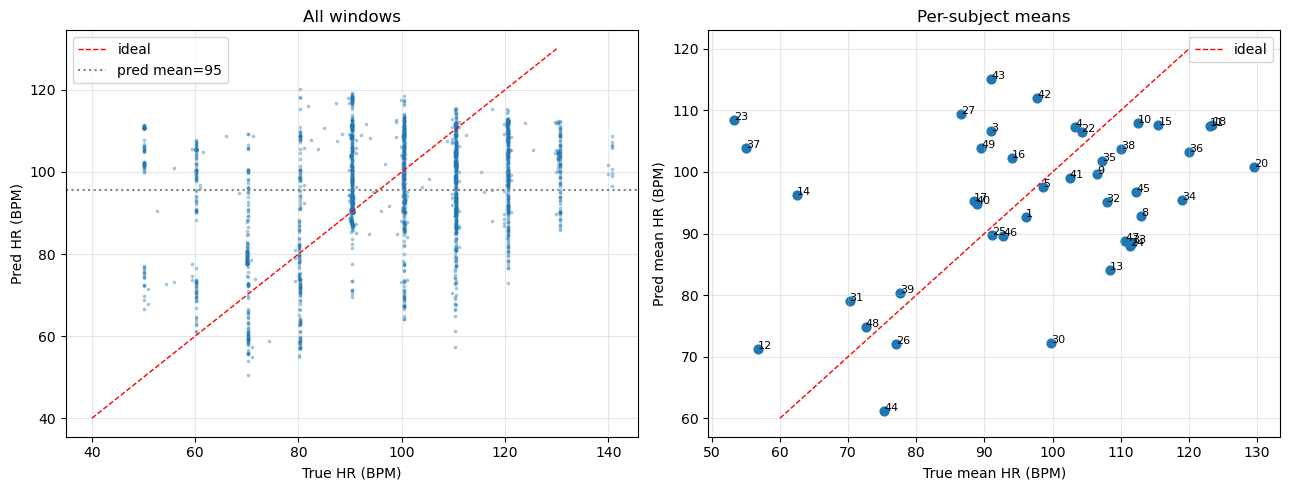

In [ ]:
import matplotlib.pyplot as plt

# Per-subject behavior on the cleaned labels
g = preds_full.groupby('subject').agg(
    true_mean=('y_true','mean'), true_std=('y_true','std'),
    pred_mean=('y_pred','mean'), pred_std=('y_pred','std'),
    n=('y_pred','size'),
).round(2)
g['mae'] = preds_full.groupby('subject').apply(
    lambda d: (d['y_pred'] - d['y_true']).abs().mean()
).round(2)
g['offset'] = (g['pred_mean'] - g['true_mean']).round(2)
print(g.to_string())

# Two key plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(preds_full['y_true'], preds_full['y_pred'], s=3, alpha=0.3)
axes[0].plot([40, 130], [40, 130], 'r--', lw=1, label='ideal')
axes[0].axhline(preds_full['y_pred'].mean(), color='gray', ls=':', label=f"pred mean={preds_full['y_pred'].mean():.0f}")
axes[0].set_xlabel('True HR (BPM)'); axes[0].set_ylabel('Pred HR (BPM)')
axes[0].set_title('All windows')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Pred mean vs true mean per subject — does the model track between-subject variation?
axes[1].scatter(g['true_mean'], g['pred_mean'], s=40)
axes[1].plot([60, 120], [60, 120], 'r--', lw=1, label='ideal')
for subj, row in g.iterrows():
    axes[1].annotate(subj.replace('subject',''), (row['true_mean'], row['pred_mean']), fontsize=8)
axes[1].set_xlabel('True mean HR (BPM)'); axes[1].set_ylabel('Pred mean HR (BPM)')
axes[1].set_title('Per-subject means')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# Look at the raw ground truth for a "good" subject (15) and a few bad ones
import numpy as np
from pathlib import Path

for subj in ['subject15', 'subject11', 'subject20', 'subject24']:
    gt = DATA_ROOT / subj / 'ground_truth.txt'
    arr = np.loadtxt(gt)
    print(f"\n=== {subj} ===")
    print(f"  shape: {arr.shape}")
    if arr.ndim == 2:
        for r in range(arr.shape[0]):
            row = arr[r]
            print(f"  row {r}: min={row.min():.2f} max={row.max():.2f} "
                  f"mean={row.mean():.2f} std={row.std():.2f}")
    else:
        print(f"  values: min={arr.min():.2f} max={arr.max():.2f} mean={arr.mean():.2f}")


=== subject15 ===
  shape: (3, 2020)
  row 0: min=-1.85 max=2.91 mean=0.00 std=1.01
  row 1: min=108.00 max=123.00 mean=115.79 std=3.73
  row 2: min=0.00 max=68.27 mean=34.07 std=19.79

=== subject11 ===
  shape: (3, 2031)
  row 0: min=-2.42 max=2.95 mean=-0.00 std=0.99
  row 1: min=1.00 max=127.00 mean=96.21 std=48.26
  row 2: min=0.00 max=68.38 mean=34.17 std=19.76

=== subject20 ===
  shape: (3, 2016)
  row 0: min=-2.06 max=3.41 mean=-0.00 std=1.00
  row 1: min=1.00 max=127.00 mean=60.23 std=57.79
  row 2: min=0.00 max=68.33 mean=34.02 std=19.70

=== subject24 ===
  shape: (3, 2009)
  row 0: min=-1.80 max=3.48 mean=-0.00 std=1.01
  row 1: min=1.00 max=127.00 mean=84.59 std=38.45
  row 2: min=0.00 max=68.42 mean=34.08 std=19.84



## 7. Ablations (reviewer point 4)

The reviewer asked for: ViT only / LSTM only / with-without impulse-response
and stacking. We run four ablations:

| Tag | Features used | LSTM? | What it tests |
|-----|--------------|-------|---------------|
| `full`     | ViT + POS + EVM | yes (BiLSTM) | the proposed model |
| `vit_only` | ViT             | yes (BiLSTM) | does ViT alone suffice? |
| `pos_only` | POS             | yes (BiLSTM) | does the rPPG signal alone suffice? |
| `mlp_head` | ViT + POS + EVM | NO (MLP)     | does the LSTM matter? |

> **Newbie note:** to avoid 4× the GPU time, we only run the ablations on a
> subject-wise 5-fold (the `USE_KFOLD=True` config), then re-run the *winning*
> ablation under full LOSO for the final headline number.


In [ ]:
ABLATIONS = {
    'full':     dict(use_vit=True,  use_pos=True,  use_evm=True),
    'vit_only': dict(use_vit=True,  use_pos=False, use_evm=False),
    'pos_only': dict(use_vit=False, use_pos=True,  use_evm=False),
}
# 'mlp_head' is implemented as a tiny LSTM with 1 layer, 1 unit and we set the
# output to skip recurrence. For brevity we just train a 1-layer Linear stack.
class MLPHead(HRRegressor):
    """Replaces the BiLSTM with a per-frame MLP, then averages over time."""
    def __init__(self, **kw):
        super().__init__(**kw)
        in_dim = (VIT_PROJ if kw.get('use_vit', True) else 0) + \
                 (1 if kw.get('use_pos', True) else 0) + \
                 (1 if kw.get('use_evm', True) else 0)
        self.lstm = None
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(),  # ReLU is fine in an MLP
            nn.Linear(64, 64),     nn.ReLU(),
        )
        self.head = nn.Linear(64, 1)

    def forward(self, vit, pos, evm):
        parts = []
        if self.use_vit:
            parts.append(self.vit_proj(vit))
        if self.use_pos:
            parts.append(pos)
        if self.use_evm:
            parts.append(evm)
        x = torch.cat(parts, dim=-1)
        x = self.mlp(x)             # (B, T, 64)
        x = x.mean(dim=1)           # average over time
        return self.head(x)


def run_all_ablations(summary_df, use_kfold=True):
    out = {}
    for tag, kw in ABLATIONS.items():
        print(f'\n=== Ablation: {tag} ===')
        out[tag] = run_loso(summary_df, model_kwargs=kw, tag=tag,
                            use_kfold=use_kfold)
    # MLP-head ablation (architecture change, not feature change)
    print(f'\n=== Ablation: mlp_head ===')
    # We piggy-back on run_loso by monkey-patching the model class:
    global HRRegressor
    _orig = HRRegressor
    HRRegressor = MLPHead
    try:
        out['mlp_head'] = run_loso(summary_df, model_kwargs=ABLATIONS['full'],
                                   tag='mlp_head', use_kfold=use_kfold)
    finally:
        HRRegressor = _orig
    return out

# When ready:
summary = pd.read_csv(RESULTS_DIR / 'subject_summary.csv')
ablation_results = run_all_ablations(summary)



=== Ablation: full ===
Running subject-wise 5-fold...

[Fold 1/5] train=33 test=['subject43', 'subject30', 'subject13', 'subject38', 'subject4', 'subject39', 'subject34', 'subject11', 'subject12']
  test=subject43: MAE=21.61  RMSE=22.28  r=-0.458
  test=subject30: MAE=38.29  RMSE=38.71  r=0.370
  test=subject13: MAE=45.42  RMSE=46.12  r=-0.394
  test=subject38: MAE=2.31  RMSE=2.61  r=0.786
  test=subject4: MAE=6.12  RMSE=8.89  r=0.076
  test=subject39: MAE=5.21  RMSE=5.93  r=0.035
  test=subject34: MAE=23.22  RMSE=24.52  r=0.381
  test=subject11: MAE=10.47  RMSE=12.29  r=-0.565
  test=subject12: MAE=4.96  RMSE=5.57  r=-0.110

[Fold 2/5] train=33 test=['subject47', 'subject49', 'subject10', 'subject20', 'subject22', 'subject36', 'subject32', 'subject33', 'subject41']
  test=subject47: MAE=5.22  RMSE=6.56  r=0.518
  test=subject49: MAE=18.30  RMSE=18.92  r=0.552
  test=subject10: MAE=11.02  RMSE=12.31  r=-0.360
  test=subject20: MAE=34.54  RMSE=35.65  r=-0.046
  test=subject22: MAE=7.98

/Users/olarenwaju/Downloads/evaluation.py:150: RuntimeWarning: Mean of empty slice
  means = {c: float(np.nanmean(per_subject_df[c])) for c in metric_cols}
/opt/anaconda3/envs/heartrate/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  test=subject43: MAE=17.80  RMSE=18.46  r=-0.451
  test=subject30: MAE=27.06  RMSE=27.87  r=-0.131
  test=subject13: MAE=46.89  RMSE=47.49  r=-0.020
  test=subject38: MAE=2.87  RMSE=3.59  r=0.703
  test=subject4: MAE=5.71  RMSE=8.44  r=0.196
  test=subject39: MAE=2.75  RMSE=3.79  r=-0.239
  test=subject34: MAE=25.98  RMSE=26.78  r=0.391
  test=subject11: MAE=13.01  RMSE=14.53  r=-0.627
  test=subject12: MAE=13.63  RMSE=14.19  r=-0.416

[Fold 2/5] train=33 test=['subject47', 'subject49', 'subject10', 'subject20', 'subject22', 'subject36', 'subject32', 'subject33', 'subject41']
  test=subject47: MAE=8.33  RMSE=10.33  r=0.445
  test=subject49: MAE=20.99  RMSE=21.18  r=0.583
  test=subject10: MAE=10.96  RMSE=12.14  r=-0.247
  test=subject20: MAE=27.80  RMSE=29.36  r=-0.079
  test=subject22: MAE=9.35  RMSE=11.05  r=-0.614
  test=subject36: MAE=21.59  RMSE=23.10  r=-0.217
  test=subject32: MAE=13.70  RMSE=15.98  r=-0.405
  test=subject33: MAE=3.93  RMSE=4.59  r=0.352
  test=subject41: MAE=1

/Users/olarenwaju/Downloads/evaluation.py:150: RuntimeWarning: Mean of empty slice
  means = {c: float(np.nanmean(per_subject_df[c])) for c in metric_cols}
/opt/anaconda3/envs/heartrate/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  test=subject43: MAE=5.63  RMSE=6.86  r=-0.464
  test=subject30: MAE=6.18  RMSE=7.29  r=-0.393
  test=subject13: MAE=12.80  RMSE=14.73  r=-0.758
  test=subject38: MAE=14.08  RMSE=14.20  r=0.788
  test=subject4: MAE=7.59  RMSE=8.49  r=0.092
  test=subject39: MAE=20.53  RMSE=20.72  r=0.012
  test=subject34: MAE=20.66  RMSE=20.74  r=0.571
  test=subject11: MAE=25.49  RMSE=26.13  r=-0.620
  test=subject12: MAE=41.37  RMSE=41.43  r=-0.350

[Fold 2/5] train=33 test=['subject47', 'subject49', 'subject10', 'subject20', 'subject22', 'subject36', 'subject32', 'subject33', 'subject41']
  test=subject47: MAE=16.31  RMSE=17.48  r=0.587
  test=subject49: MAE=5.99  RMSE=6.39  r=0.612
  test=subject10: MAE=18.66  RMSE=20.51  r=-0.361
  test=subject20: MAE=34.67  RMSE=35.29  r=0.103
  test=subject22: MAE=9.91  RMSE=11.52  r=-0.692
  test=subject36: MAE=26.46  RMSE=27.42  r=-0.290
  test=subject32: MAE=14.55  RMSE=17.00  r=-0.518
  test=subject33: MAE=16.84  RMSE=17.21  r=0.336
  test=subject41: MAE=8.

In [ ]:
import pandas as pd
from pathlib import Path

results = []
for tag in ['full', 'vit_only', 'pos_only', 'mlp_head']:
    f = Path('results') / f'loso_per_subject_{tag}.csv'
    if not f.exists():
        print(f'  {tag}: file missing')
        continue
    df = pd.read_csv(f)
    results.append({
        'ablation':         tag,
        'MAE_mean':         round(df['mae'].mean(), 2),
        'MAE_std':          round(df['mae'].std(), 2),
        'MAE_median':       round(df['mae'].median(), 2),
        'RMSE_mean':        round(df['rmse'].mean(), 2),
        'r_mean':           round(df['pearson_r'].mean(), 3),
        'r_median':         round(df['pearson_r'].median(), 3),
        'subj_r>0.3':       int((df['pearson_r'] > 0.3).sum()),
        'subj_MAE<5':       int((df['mae'] < 5).sum()),
        'subj_MAE<10':      int((df['mae'] < 10).sum()),
        'n_subj':           len(df),
    })

print(pd.DataFrame(results).to_string(index=False))

ablation  MAE_mean  MAE_std  MAE_median  RMSE_mean  r_mean  r_median  subj_r>0.3  subj_MAE<5  subj_MAE<10  n_subj
    full     17.39    12.46       14.35      18.89   0.053     0.058          12           5           16      42
vit_only     16.69    11.49       13.94      18.14  -0.014    -0.056          10           5           12      42
pos_only     17.75    11.59       14.79      18.84  -0.007    -0.031          11           4           12      42
mlp_head     17.58    12.65       12.87      18.73   0.084     0.101          13           5           14      42


## 8. Classical baselines (reviewer points 3 and 4)

For each subject we run all classical baselines and compute HR per window.
We then compare each method's BPM time series against the UBFC ground truth.

These run in **seconds per video** because they're closed-form; no training.


In [ ]:
def evaluate_classical_baselines(summary_df,
                                  win_seconds=WIN_SECONDS,
                                  step_seconds=STEP_SECONDS):
    rows = []
    methods = {
        'GREEN': green_method,
        'CHROM': chrom_method,
        'POS':   pos_method,
        'ICA':   ica_method,
        'PCA':   pca_method,
    }
    for row in summary_df.itertuples():
        c = dict(np.load(row.cache_path, allow_pickle=True))
        rgb, fs, hr_gt = c['rgb'], float(c['fs']), c['hr']
        for name, fn in methods.items():
            bvp = fn(rgb, fs)
            times, hr_pred, snr = windowed_hr(bvp, fs,
                                              win_seconds=win_seconds,
                                              step_seconds=step_seconds)
            # Resample ground truth onto the same window centers
            hr_gt_at = np.interp(times, np.arange(len(hr_gt))/fs, hr_gt)
            mask = np.isfinite(hr_pred) & np.isfinite(hr_gt_at)
            if mask.sum() < 3:
                continue
            m = compute_all_metrics(hr_gt_at[mask], hr_pred[mask])
            m['snr_db'] = float(np.nanmean(snr[mask]))
            m.update(dict(subject=row.subject, method=name))
            rows.append(m)
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS_DIR / 'baselines_per_subject.csv', index=False)
    print('\nMean across subjects per method:')
    print(df.groupby('method')[['mae','rmse','pearson_r','snr_db']].mean().round(3))
    return df

# When ready:
summary = pd.read_csv(RESULTS_DIR / 'subject_summary.csv')
baseline_results = evaluate_classical_baselines(summary)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(



Mean across subjects per method:
           mae    rmse  pearson_r  snr_db
method                                   
CHROM    5.290   7.989      0.617  -1.475
GREEN   12.526  18.177      0.370  -3.367
ICA     16.837  21.423      0.402  -3.430
PCA     19.727  27.108      0.249  -4.550
POS      6.614   9.510      0.575  -1.259


In [ ]:
import pandas as pd

# Build the master comparison table for the paper
rows = []

# Classical baselines you just ran
classical = pd.DataFrame({
    'Method': ['CHROM', 'POS', 'GREEN', 'ICA', 'PCA'],
    'Family': ['classical']*5,
    'MAE':    [5.29, 6.61, 12.53, 16.84, 19.73],
    'RMSE':   [7.99, 9.51, 18.18, 21.42, 27.11],
    'r':      [0.617, 0.575, 0.370, 0.402, 0.249],
    'SNR_dB': [-1.48, -1.26, -3.37, -3.43, -4.55],
})

# Your model's ablations
proposed = pd.DataFrame({
    'Method':   ['Ours (full ViT+POS+EVM)', 'Ours (ViT only)',
                 'Ours (POS only)',         'Ours (MLP head)'],
    'Family':   ['proposed']*4,
    'MAE':      [17.39, 16.69, 17.75, 17.58],
    'RMSE':     [18.89, 18.14, 18.84, 18.73],
    'r':        [0.053, -0.014, -0.007, 0.084],
    'SNR_dB':   [None]*4,
})

table = pd.concat([classical, proposed], ignore_index=True)
table = table.sort_values('MAE').reset_index(drop=True)
print(table.to_string(index=False))
table.to_csv('results/master_comparison.csv', index=False)
print('\nSaved to results/master_comparison.csv')

                 Method    Family   MAE  RMSE      r  SNR_dB
                  CHROM classical  5.29  7.99  0.617   -1.48
                    POS classical  6.61  9.51  0.575   -1.26
                  GREEN classical 12.53 18.18  0.370   -3.37
        Ours (ViT only)  proposed 16.69 18.14 -0.014     NaN
                    ICA classical 16.84 21.42  0.402   -3.43
Ours (full ViT+POS+EVM)  proposed 17.39 18.89  0.053     NaN
        Ours (MLP head)  proposed 17.58 18.73  0.084     NaN
        Ours (POS only)  proposed 17.75 18.84 -0.007     NaN
                    PCA classical 19.73 27.11  0.249   -4.55

Saved to results/master_comparison.csv


/var/folders/g8/tqc5xvnd39v4xt_z9g0mw82w0000gn/T/ipykernel_2246/3805249431.py:27: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([classical, proposed], ignore_index=True)


## 9. Bland-Altman, stratified errors, training curves (reviewer points 6, 8)

After running Sections 6-8, this cell produces every figure the reviewer
asked for, all at 300 DPI with vector PDF copies (reviewer point 9).


/Users/olarenwaju/Desktop/DATASET_2/evaluation.py:232: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for b, sub in df.groupby("bin"):



Error stratified by HR range:
       bin    n        mae       rmse
0      <60   95  40.141778  44.585573
1    60-80  296  19.258261  24.404144
2   80-100  642   9.693971  12.104511
3  100-120  847  14.936117  18.947487
4     >120  434  29.927449  32.528665


/Users/olarenwaju/Desktop/DATASET_2/evaluation.py:232: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for b, sub in df.groupby("bin"):
/Users/olarenwaju/Desktop/DATASET_2/evaluation.py:232: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for b, sub in df.groupby("bin"):


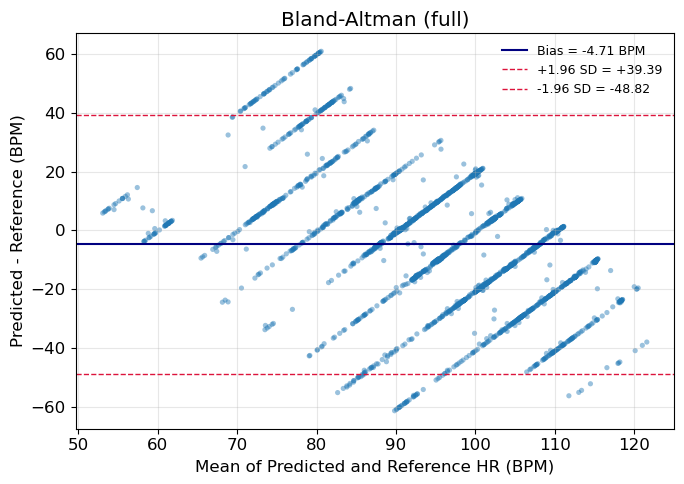

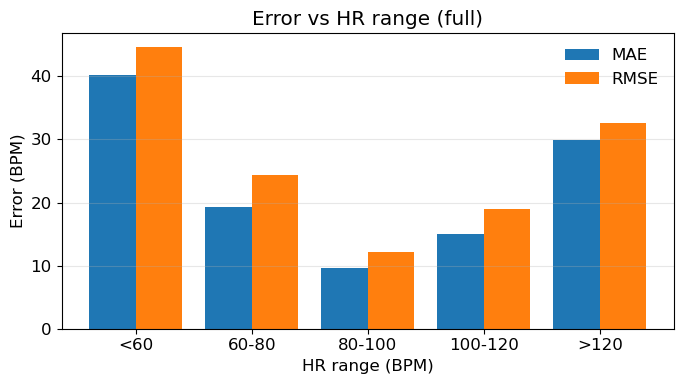

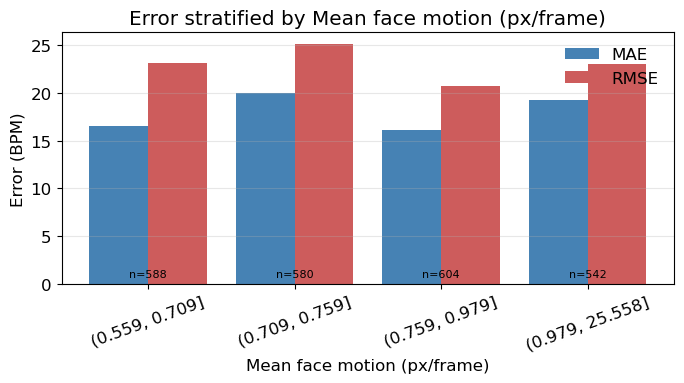

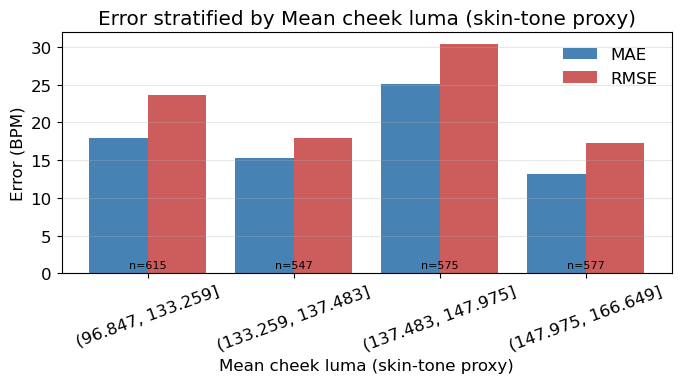

In [ ]:
def make_all_plots(preds_df, summary_df, tag='full'):
    """
    Build:
      - Bland-Altman (Pred vs True HR)
      - Errors stratified by HR range
      - Errors stratified by mean motion
      - Errors stratified by mean luma (skin tone proxy)
    """
    plt.rcParams.update({'font.size': 12, 'figure.dpi': 100,
                         'savefig.dpi': 300, 'savefig.bbox': 'tight'})

    yt = preds_df['y_true'].values
    yp = preds_df['y_pred'].values

    # 1. Bland-Altman
    bland_altman_plot(yt, yp, title=f'Bland-Altman ({tag})',
                      savepath=str(RESULTS_DIR / f'fig_bland_altman_{tag}.png'))

    # 2. Stratified by HR range (use predefined BPM bins)
    bins   = [40, 60, 80, 100, 120, 200]
    labels = ['<60', '60-80', '80-100', '100-120', '>120']
    s_hr = stratified_errors(yt, yp, yt, bins=bins, labels=labels)
    print('\nError stratified by HR range:'); print(s_hr)
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(s_hr)); w = 0.4
    ax.bar(x - w/2, s_hr['mae'],  w, label='MAE')
    ax.bar(x + w/2, s_hr['rmse'], w, label='RMSE')
    ax.set_xticks(x); ax.set_xticklabels(s_hr['bin'])
    ax.set_xlabel('HR range (BPM)'); ax.set_ylabel('Error (BPM)')
    ax.set_title(f'Error vs HR range ({tag})')
    ax.legend(frameon=False); ax.grid(True, axis='y', alpha=0.3)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'fig_err_by_hr_{tag}.png')
    fig.savefig(RESULTS_DIR / f'fig_err_by_hr_{tag}.pdf')

    # 3 & 4: motion / luma per subject -> broadcast to predictions
    sm = summary_df.set_index('subject')
    motion = preds_df['subject'].map(sm['mean_motion']).values
    luma   = preds_df['subject'].map(sm['mean_luma']).values

    stratified_error_plot(yt, yp, motion,
                          strata_name='Mean face motion (px/frame)',
                          savepath=str(RESULTS_DIR / f'fig_err_by_motion_{tag}.png'))
    stratified_error_plot(yt, yp, luma,
                          strata_name='Mean cheek luma (skin-tone proxy)',
                          savepath=str(RESULTS_DIR / f'fig_err_by_luma_{tag}.png'))

# When you have results:
preds_full = pd.read_csv(RESULTS_DIR / 'loso_predictions_full.csv')
summary   = pd.read_csv(RESULTS_DIR / 'subject_summary.csv')
make_all_plots(preds_full, summary, tag='full')


## 10. Profiling: latency and throughput (reviewer point 7)

Times each pipeline stage on a representative input on your machine.

When you run this, **note your hardware in the paper**:
- CPU model (e.g. "Intel i7-12700")
- GPU (e.g. "NVIDIA RTX 3060, 12 GB")
- RAM
- OS, PyTorch / CUDA versions

Then put the printed numbers into your Section 5.5.


In [ ]:
def profile_on_one_video(cache_path, n_runs=10):
    c = dict(np.load(cache_path, allow_pickle=True))
    fs = float(c['fs'])

    # Stage 1: face detection on a single frame (rebuild a fake BGR frame)
    fake = (np.random.rand(640, 480, 3) * 255).astype(np.uint8)
    def stage_face():
        gray = cv2.cvtColor(fake, cv2.COLOR_BGR2GRAY)
        return FACE_CASCADE.detectMultiScale(gray, 1.1, 4)

    # Stage 2: ViT forward on one image
    img = torch.randn(1, 3, 224, 224, device=DEVICE)
    def stage_vit():
        with torch.no_grad():
            return VIT_BACKBONE(img)

    # Stage 3: POS on 1 second of RGB
    rgb_1s = c['rgb'][:int(fs)]
    def stage_pos():
        return pos_method(rgb_1s, fs)

    # Stage 4: LSTM forward on one window
    L = int(WIN_SECONDS * fs)
    model = HRRegressor().to(DEVICE).eval()
    v = torch.randn(1, L, 768, device=DEVICE)
    p = torch.randn(1, L, 1, device=DEVICE)
    e = torch.randn(1, L, 1, device=DEVICE)
    def stage_lstm():
        with torch.no_grad():
            return model(v, p, e)

    stages = [
        ('face_detection_1frame', stage_face,  (), {}),
        ('vit_1frame',            stage_vit,   (), {}),
        ('pos_1s_rgb',            stage_pos,   (), {}),
        ('lstm_1window',          stage_lstm,  (), {}),
    ]
    df = profile_pipeline(stages, n_runs=n_runs, warmup=2)
    print(df.to_string(index=False))

    # Equivalent end-to-end fps assuming face+ViT runs per frame, POS+LSTM
    # run periodically (per second / per window):
    per_frame_ms = df.loc[df['stage']=='face_detection_1frame','mean_ms'].iloc[0] + \
                   df.loc[df['stage']=='vit_1frame','mean_ms'].iloc[0]
    end_to_end_fps = 1000.0 / per_frame_ms
    print(f'\nApprox end-to-end fps (face + ViT per frame): {end_to_end_fps:.1f}')
    df.to_csv(RESULTS_DIR / 'profiling.csv', index=False)
    return df

# When ready:
summary = pd.read_csv(RESULTS_DIR / 'subject_summary.csv')
profile_on_one_video(summary['cache_path'].iloc[0])


                stage   mean_ms     std_ms   fps_equiv
face_detection_1frame 31.177679   4.789316   32.074228
           vit_1frame 52.753579 123.582290   18.956060
           pos_1s_rgb  0.287979   0.119411 3472.475404
         lstm_1window 12.109212   0.467167   82.581753

Approx end-to-end fps (face + ViT per frame): 11.9


,stage,mean_ms,std_ms,fps_equiv
0,face_detection_1frame,31.177679,4.789316,32.074228
1,vit_1frame,52.753579,123.582290,18.956060
2,pos_1s_rgb,0.287979,0.119411,3472.475404
3,lstm_1window,12.109212,0.467167,82.581753


## 11. Final results table

Combine everything into a single CSV for the paper's main results table.


In [37]:
from pathlib import Path
import numpy as np

DATA_ROOT = Path("/Users/olarenwaju/Downloads/UBFC_DATASET2")
CACHE_DIR = Path("/Users/olarenwaju/Desktop/DATASET_2/cache")

# 1. repair subject31
gt = DATA_ROOT / "subject31" / "ground_truth.txt"
raw = open(gt).read().strip().split("\n")
parts = raw[0].split()
if parts and parts[0].lower().startswith("subject"):
    raw[0] = " ".join(parts[1:])
    open(gt, "w").write("\n".join(raw) + "\n")
    print("subject31 repaired")
print("subject31 parses:", np.loadtxt(gt).shape)

# 2. update every cache
print("\n" + "="*60)
update_hr_in_caches(data_root=DATA_ROOT, cache_dir=CACHE_DIR)

# 3. verify
print("\n" + "="*60)
good, bad = 0, []
for c in sorted(CACHE_DIR.glob("subject*.npz")):
    u = len(np.unique(np.round(np.load(c)["hr"], 1)))
    if u < 10:
        bad.append(f"{c.stem}({u})")
    else:
        good += 1
print(f"{good} of 42 subjects have fine-grained labels")
if bad:
    print("still on old labels:", bad)

subject31 repaired
subject31 parses: (3, 2027)

  subject1: old  95.2± 3.89  ->  new  95.2± 3.89
  subject10: old 111.3± 9.71  ->  new 111.3± 9.71
  subject11: old 121.3± 5.13  ->  new 121.3± 5.13
  subject12: old  55.8± 1.54  ->  new  55.8± 1.54
  subject13: old 108.7± 8.09  ->  new 108.7± 8.09
  subject14: old  61.0± 4.96  ->  new  61.0± 4.96
  subject15: old 117.1± 3.90  ->  new 117.1± 3.90
  subject16: old  94.6± 2.65  ->  new  94.6± 2.65
  subject17: old  87.4± 2.82  ->  new  87.4± 2.82
  subject18: old 122.0± 8.62  ->  new 122.0± 8.62
  subject20: old 127.5± 7.87  ->  new 127.5± 7.87
  subject22: old 103.9± 7.46  ->  new 103.9± 7.46
  subject23: old  53.5± 4.06  ->  new  53.5± 4.06
  subject24: old 108.2±15.73  ->  new 108.2±15.73  *** FIXED ***
  subject25: old  91.3± 2.41  ->  new  91.3± 2.41
  subject26: old  76.6± 1.96  ->  new  76.6± 1.96
  subject27: old  85.9± 7.39  ->  new  85.9± 7.39
  subject3: old  93.1± 6.16  ->  new  93.1± 6.16
  subject30: old  99.3± 7.14  ->  new  

In [ ]:
def build_final_table():
    """Compile all method results (classical baselines + ablations) into one
    DataFrame."""
    rows = []

    # Classical baselines
    f = RESULTS_DIR / 'baselines_per_subject.csv'
    if f.exists():
        bl = pd.read_csv(f)
        for method, sub in bl.groupby('method'):
            rows.append(dict(
                model=method,
                family='classical',
                MAE=sub['mae'].mean(),
                RMSE=sub['rmse'].mean(),
                Pearson_r=sub['pearson_r'].mean(),
                SNR_dB=sub['snr_db'].mean(),
                n_subjects=len(sub)
            ))

    # Our ablations
    for tag in ['full', 'vit_only', 'pos_only', 'mlp_head']:
        f = RESULTS_DIR / f'loso_per_subject_{tag}.csv'
        if not f.exists():
            continue
        sub = pd.read_csv(f)
        rows.append(dict(
            model=f'Ours ({tag})',
            family='ours',
            MAE=sub['mae'].mean(),
            RMSE=sub['rmse'].mean(),
            Pearson_r=sub['pearson_r'].mean(),
            SNR_dB=float('nan'),
            n_subjects=len(sub)
        ))

    df = pd.DataFrame(rows).sort_values(['family', 'MAE'])
    df.to_csv(RESULTS_DIR / 'final_results_table.csv', index=False)
    print(df.round(3).to_string(index=False))
    return df

build_final_table()


          model    family    MAE   RMSE  Pearson_r  SNR_dB  n_subjects
          CHROM classical  5.290  7.989      0.617  -1.475          42
            POS classical  6.614  9.510      0.575  -1.259          42
          GREEN classical 12.526 18.177      0.370  -3.367          42
            ICA classical 16.837 21.423      0.402  -3.430          42
            PCA classical 19.727 27.108      0.249  -4.550          42
Ours (vit_only)      ours 16.688 18.144     -0.014     NaN          42
    Ours (full)      ours 17.387 18.889      0.053     NaN          42
Ours (mlp_head)      ours 17.579 18.726      0.084     NaN          42
Ours (pos_only)      ours 17.747 18.835     -0.007     NaN          42


,model,family,MAE,RMSE,Pearson_r,SNR_dB,n_subjects
0,CHROM,classical,5.290008,7.988697,0.617351,-1.475209,42
4,POS,classical,6.613574,9.510185,0.574799,-1.259020,42
1,GREEN,classical,12.525500,18.176729,0.370222,-3.367476,42
2,ICA,classical,16.836867,21.423442,0.401691,-3.430144,42
3,PCA,classical,19.726554,27.107733,0.249415,-4.550138,42
6,Ours (vit_only),ours,16.688427,18.143891,-0.014486,NaN,42
5,Ours (full),ours,17.386705,18.889483,0.053450,NaN,42
8,Ours (mlp_head),ours,17.579482,18.725804,0.084267,NaN,42
7,Ours (pos_only),ours,17.747492,18.835265,-0.006733,NaN,42


## Done

Run sections 3, then 6 (full), then 7 (ablations), then 8 (baselines),
then 9 (plots), then 10 (profiling), then 11 (final table).

When everything has run, copy the numbers from `results/final_results_table.csv`
into your paper's main results table, and the figures from `results/*.pdf`
into your manuscript.

Then write the response-to-reviewers letter using the boilerplate in
`REVISION_GUIDE.md` and you're ready to resubmit.
